# W2 From exploratory analysis to credible validation
**Group 09 · Ariel Cusacovich and Ana Peris Diaz-Varela · 29 October 2026**

We continue our W1 respiratory project and C1 investigation of emergency visits among children under 15 in Metropolitan Region hospitals in 2023–2024. Our decision remains **when and where a hospital-network planning team should investigate demand**, before considering resource changes. We use a hospital-network planning team as the intended audience; we have not conducted stakeholder interviews. Counts cannot determine staffing requirements or disease incidence.

**Question:** How did recorded respiratory emergency demand change, and how credible is that conclusion after correcting C1, examining coverage, and separating development from a temporal robustness check?

**KPI:** respiratory share = 100 × respiratory visits under 15 / all-cause visits under 15, with identical hospitals and dates in numerator and denominator. Supporting measures are visit counts and visits per calendar day. The source unit is a **hospital–date–cause aggregate**, not a patient; the paired analytical unit is a **hospital-day**. Network daily figures sum these hospital-days.

Our group is **09**. The Group 10 label in the W1 archive and on the C1 slide cover was incorrect. We keep the original files in `legacy/` for reference and use Group 09 in this submission. We continue the respiratory question selected in C1.

Run all cells in order from this folder or the repository root. No network access is needed with the supplied data. The default reads every row of the original annual ZIPs. All narrative is in English; official source names and original fields remain in Spanish for traceability.

## 1. Reproducible settings and analysis protocol
We use a fixed seed of 42. The historical 22-hospital panel reproduces C1, while **all 26 observed hospitals** support coverage comparisons, sampling and time-based validation. This avoids using 2024 completeness to select the validation population. The 26 IDs are defined from 2023 and checked for new 2024 IDs.

The development pool is January 2023–June 2024. Within it, **2023 is fitting data** and **January–June 2024 is internal validation**. July–December 2024 is test data. We chose calendar boundaries so that each period is easy to interpret; we did not optimize them to obtain a particular result. W1/C1 already explored both years: this is a retrospective, disjoint temporal robustness exercise, **not an untouched confirmatory test or a claim of forecasting accuracy**. We do not fit a predictive model in W2.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import hashlib, json, sys, platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'data/source/sources.csv').exists(), 'Run from the project root or notebooks folder.'
SEED = 42
REBUILD_FROM_SOURCE = True
TRAIN_END = pd.Timestamp('2023-12-31')
VALIDATION_END = pd.Timestamp('2024-06-30')
sources = ROOT / 'data/source'
inputs = ROOT / 'data/inputs'
clean = ROOT / 'data/clean'
tables = ROOT / 'data/outputs/tables'
figures = ROOT / 'data/outputs/figures'
splits_dir = ROOT / 'data/splits'
for folder in [inputs, clean, tables, figures, splits_dir]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 80)
pd.set_option('display.float_format', '{:,.4f}'.format)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
COLORS = ['#167D8D','#D47938']
def save_table(frame, name, show=True):
    frame.to_csv(tables / (name+'.csv'), index=False)
    if show:
        display(frame)
def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(figures / (name+'.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def sha256(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()
print('Group 09 | seed:', SEED, '| Python:', platform.python_version())

Group 09 | seed: 42 | Python: 3.12.14


## 2. Source provenance and reconstruction
We use the same DEIS/MINSAL source files as in W1 and C1. The source register records retrieval and verification on 25 September 2026. Here we check each local file against its recorded SHA-256 fingerprint. This does not establish when each observation became available to a planner. Each annual CSV is scanned completely in chunks. The explicit filters are provider region 13, establishment type Hospital, and cause 1 (all emergencies) or 2 (respiratory emergencies). No patient-level records are used.

The reduced files are full extracts of the selected scope, not random samples. Source totals and respiratory totals overlap and must never be added together. The dictionary's older facility annex is not joined. The provided extracts allow an offline quick rerun with `REBUILD_FROM_SOURCE=False`; their fingerprints are checked as well.

In [2]:
manifest = pd.read_csv(sources / 'sources.csv')
fingerprints = []
for row in manifest.itertuples():
    path = sources / row.file
    if REBUILD_FROM_SOURCE or path.exists():
        assert path.exists(), f'Missing source: {path}'
        digest = sha256(path)
        assert digest == row.sha256, f'Source fingerprint mismatch: {row.file}'
        fingerprints.append({'file':row.file,'sha256':digest,'verified_local':True})
save_table(pd.DataFrame(fingerprints),'source_checksums')
extract_manifest = pd.read_csv(inputs / 'extract_manifest.csv')
scan_log = []
for year in [2023,2024]:
    out = inputs / f'respiratory_RM_{year}_raw.csv'
    if REBUILD_FROM_SOURCE:
        parts=[]; scanned=0
        with ZipFile(sources / f'AtencionesUrgencia{year}.zip') as archive:
            names=[n for n in archive.namelist() if n.lower().endswith('.csv')]
            assert len(names)==1
            with archive.open(names[0]) as original:
                for chunk in pd.read_csv(original,sep=';',encoding='latin1',dtype=str,chunksize=200000):
                    scanned += len(chunk)
                    mask=(chunk['CodigoRegion']=='13') & (chunk['GLOSATIPOESTABLECIMIENTO']=='Hospital') & chunk['IdCausa'].isin(['1','2'])
                    parts.append(chunk.loc[mask].copy())
        extract=pd.concat(parts,ignore_index=True)
        extract.to_csv(out,index=False)
    else:
        scanned = None
        extract=pd.read_csv(out,dtype=str)
    expected=extract_manifest.set_index('file').loc[out.name,'sha256']
    # Normalize only CSV line endings so the fingerprint is portable across operating systems.
    extract_digest=hashlib.sha256(out.read_bytes().replace(bytes([13,10]),bytes([10]))).hexdigest()
    assert extract_digest==expected, 'Extract differs from the reviewed snapshot.'
    scan_log.append({'year':year,'source_rows_scanned_this_run':scanned,'selected_rows':len(extract),'columns':len(extract.columns),'mode':'full-source' if REBUILD_FROM_SOURCE else 'verified-extract'})
save_table(pd.DataFrame(scan_log),'extraction_summary')
raw_parts=[pd.read_csv(inputs / f'respiratory_RM_{y}_raw.csv',dtype={'IdEstablecimiento':str}) for y in [2023,2024]]
assert list(raw_parts[0].columns)==list(raw_parts[1].columns)
raw=pd.concat(raw_parts,ignore_index=True)
dictionary=pd.read_excel(sources/'Diccionario_AtencionesUrgencia.xlsx',sheet_name='Anexo 1',header=None,usecols=[2,3])
dictionary.columns=['IdCausa','official_description']
dictionary=dictionary[dictionary.IdCausa.isin([1,2])].copy()
assert set(dictionary.IdCausa)=={1,2}
save_table(dictionary,'cause_dictionary')
save_table(pd.DataFrame({'variable':raw.columns,'dtype':raw.dtypes.astype(str).values,'missing_cells':raw.isna().sum().values,'distinct_values':raw.nunique(dropna=False).values}),'variable_profile')

,file,sha256,verified_local
0,AtencionesUrgencia2024.zip,aabe39d2f0f121aaf222f1d60b38bbaa34aabf9adf306f31d449834e8c6ca8f0,True
1,AtencionesUrgencia2023.zip,b11e6214a381843904632e3aed75c4f04b7d7fc2c275b2da418eac6451192836,True
2,Diccionario_AtencionesUrgencia.xlsx,f179a826b7a8e903a5cc44381dcf0fb1f5f6ff21beceebf434e07bb0d1e1a105,True


,year,source_rows_scanned_this_run,selected_rows,columns,mode
0,2023,8899080,18974,21,full-source
1,2024,8973229,19002,21,full-source


,IdCausa,official_description
7,1,SECCIÓN 1. TOTAL ATENCIONES DE URGENCIA
8,2,TOTAL CAUSAS SISTEMA RESPIRATORIO


,variable,dtype,missing_cells,distinct_values
0,IdEstablecimiento,str,0,26
1,NEstablecimiento,str,0,28
2,IdCausa,int64,0,2
3,GlosaCausa,str,0,2
4,Total,int64,0,592
5,Menores_1,int64,0,70
6,De_1_a_4,int64,0,121
7,De_5_a_14,int64,0,230
8,De_15_a_64,int64,0,293
9,De_65_y_mas,int64,0,93


## 3. Data dictionary, validation and treatment
Count values are recorded visits; zero is a recorded count, whereas a missing hospital-day is an absent report. No absent day is filled with zero. Missing values in required identifiers/counts would stop execution for investigation. Missing publication timestamps are **unobserved**, not evidence of immediate availability. The source week field is retained but not assumed to be ISO week. Date parsing follows the actual `dd/mm/yyyy` files rather than the older dictionary's punctuation.

In [3]:
data_dictionary = pd.DataFrame([
 ('IdEstablecimiento / id','text','Nonempty stable hospital ID; trim surrounding whitespace only','Missing ID invalid; never infer from hospital name'),
 ('fecha / date','date','2023-01-01 through 2024-12-31; source dd/mm/yyyy','Missing date invalid'),
 ('IdCausa','integer category','1 all emergencies; 2 respiratory subset','Missing cause invalid'),
 ('Total','integer count','Nonnegative; equal sum of five age groups','Missing not zero'),
 ('Menores_1','integer count','Visits under age 1; nonnegative','Missing not zero'),
 ('De_1_a_4','integer count','Visits ages 1–4; nonnegative','Missing not zero'),
 ('De_5_a_14','integer count','Visits ages 5–14; nonnegative','Missing not zero'),
 ('De_15_a_64 / De_65_y_mas','integer counts','Older age groups, used for total reconciliation','Missing not zero'),
 ('under_15','integer count','Sum of first three age columns, within one cause','Undefined if an input age count is missing'),
 ('CodigoRegion / GLOSATIPOESTABLECIMIENTO','categories','13 / Hospital in this extract','Provider location; not patient residence'),
 ('NEstablecimiento','text label','Official observed name; never use as key','Name variation does not imply a new hospital'),
 ('GLOSATIPOATENCION / GlosaTipoCampana','text categories','Retain original service/campaign labels','Not assumed to be patient attributes'),
 ('respiratory / all_cause','integer counts','Paired under-15 values from causes 2 / 1','Unmatched causes invalid'),
 ('share_pct','decimal percent','100 × respiratory / all_cause; 0–100 when defined','Undefined when all_cause is zero'),
 ('lag7_resp','decimal or missing','Same hospital count exactly seven calendar days earlier','Missing earlier report/history; training-only imputation for demo'),
 ('published_at','not supplied','Would be needed to establish prospective availability','Unknown; no operational forecasting claim')
],columns=['variable','expected_type','definition_and_constraint','missing_value_meaning'])
save_table(data_dictionary,'data_dictionary')
df=raw.copy()
df['id']=df.IdEstablecimiento.str.strip()
df['date']=pd.to_datetime(df.fecha,format='%d/%m/%Y',errors='coerce')
df['year']=df.date.dt.year
df['month']=df.date.dt.month
ages=['Menores_1','De_1_a_4','De_5_a_14','De_15_a_64','De_65_y_mas']
count_cols=['Total']+ages
for col in count_cols:
    df[col]=pd.to_numeric(df[col],errors='coerce')
df['under_15']=df[ages[:3]].sum(axis=1,min_count=3)
checks=[]
def check(name, failures, action='Retained after check', blocking=True):
    checks.append({'check':name,'affected':int(failures),'status':'PASS' if failures==0 else ('FAIL' if blocking else 'REVIEW'),'action':action})
check('Missing source cells',raw.isna().sum().sum())
check('Missing or empty IDs',df.id.isna().sum()+df.id.eq('').sum())
check('Invalid or out-of-period dates',(~df.date.between('2023-01-01','2024-12-31')).sum())
check('Invalid numeric cells',df[count_cols].isna().sum().sum())
check('Negative counts',(df[count_cols]<0).sum().sum())
check('Noninteger counts',(df[count_cols]%1!=0).sum().sum())
check('Duplicate hospital-date-cause keys',df.duplicated(['id','date','IdCausa']).sum())
check('Age sum differs from Total',(df.Total!=df[ages].sum(axis=1)).sum())
check('Unexpected selected scope',((df.CodigoRegion!=13)|(df.GLOSATIPOESTABLECIMIENTO!='Hospital')|~df.IdCausa.isin([1,2])).sum())
check('Whitespace in source ID',(raw.IdEstablecimiento!=df.id).sum(),'CORRECTED only in derived id; original retained',False)
check('Recorded zero child counts',df.under_15.eq(0).sum(),'RETAINED; zero is not an absent record',False)
check('IDs with multiple display names',(df.groupby('id').NEstablecimiento.nunique()>1).sum(),'RETAINED; group by stable ID',False)
quality=pd.DataFrame(checks)
save_table(quality,'quality_checks_initial')
assert not (quality.status=='FAIL').any(), 'Investigate failed quality checks before continuing.'
paired=df.pivot(index=['id','date'],columns='IdCausa',values='under_15').rename(columns={1:'all_cause',2:'respiratory'}).reset_index()
check('Unmatched hospital-day causes',paired[['all_cause','respiratory']].isna().sum().sum())
check('Respiratory exceeds same-age all-cause',(paired.respiratory>paired.all_cause).sum())
for age in ages[:3]:
    a=df.pivot(index=['id','date'],columns='IdCausa',values=age)
    check('Respiratory exceeds all-cause: '+age,(a[2]>a[1]).sum())
expected_labels=dictionary.set_index('IdCausa').official_description.str.strip()
check('Cause labels disagree with dictionary',(df.GlosaCausa.str.strip()!=df.IdCausa.map(expected_labels)).sum())
names=df.sort_values('date').groupby('id').NEstablecimiento.last()
check('Unmapped hospital labels',paired.id.map(names).isna().sum())
assert not (pd.DataFrame(checks).status=='FAIL').any()
before=raw.groupby('IdCausa')[count_cols].sum()
after=df.groupby('IdCausa')[count_cols].sum()
pd.testing.assert_frame_equal(before,after,check_dtype=False)
assert len(df)==len(raw)
save_table(before.add_suffix('_before').join(after.add_suffix('_after')).reset_index(),'before_after_totals')

,variable,expected_type,definition_and_constraint,missing_value_meaning
0,IdEstablecimiento / id,text,Nonempty stable hospital ID; trim surrounding whitespace only,Missing ID invalid; never infer from hospital name
1,fecha / date,date,2023-01-01 through 2024-12-31; source dd/mm/yyyy,Missing date invalid
2,IdCausa,integer category,1 all emergencies; 2 respiratory subset,Missing cause invalid
3,Total,integer count,Nonnegative; equal sum of five age groups,Missing not zero
4,Menores_1,integer count,Visits under age 1; nonnegative,Missing not zero
5,De_1_a_4,integer count,Visits ages 1–4; nonnegative,Missing not zero
6,De_5_a_14,integer count,Visits ages 5–14; nonnegative,Missing not zero
7,De_15_a_64 / De_65_y_mas,integer counts,"Older age groups, used for total reconciliation",Missing not zero
8,under_15,integer count,"Sum of first three age columns, within one cause",Undefined if an input age count is missing
9,CodigoRegion / GLOSATIPOESTABLECIMIENTO,categories,13 / Hospital in this extract,Provider location; not patient residence


,check,affected,status,action
0,Missing source cells,0,PASS,Retained after check
1,Missing or empty IDs,0,PASS,Retained after check
2,Invalid or out-of-period dates,0,PASS,Retained after check
3,Invalid numeric cells,0,PASS,Retained after check
4,Negative counts,0,PASS,Retained after check
5,Noninteger counts,0,PASS,Retained after check
6,Duplicate hospital-date-cause keys,0,PASS,Retained after check
7,Age sum differs from Total,0,PASS,Retained after check
8,Unexpected selected scope,0,PASS,Retained after check
9,Whitespace in source ID,2902,REVIEW,CORRECTED only in derived id; original retained


,IdCausa,Total_before,Menores_1_before,De_1_a_4_before,De_5_a_14_before,De_15_a_64_before,De_65_y_mas_before,Total_after,Menores_1_after,De_1_a_4_after,De_5_a_14_after,De_15_a_64_after,De_65_y_mas_after
0,1,3197569,194086,391744,649102,1458116,504521,3197569,194086,391744,649102,1458116,504521
1,2,495167,81075,138314,128857,98003,48918,495167,81075,138314,128857,98003,48918


### Calendar coverage and saved data
The complete historical panel requires both causes on all 365 days of 2023 and all 366 days of 2024. It is retained only to reproduce C1 and inspect sensitivity. It is a selection on reporting completeness, not a probability sample. The validation dataset instead uses the hospital IDs observed in 2023 and retains all their available hospital-days.

In [4]:
universe_2023=set(df.loc[df.year==2023,'id'])
new_ids=set(df.loc[df.year==2024,'id'])-universe_2023
check('New 2024 IDs outside 2023 universe',len(new_ids))
assert not new_ids, 'New hospitals require a declared validation-scope decision.'
coverage_index=pd.MultiIndex.from_product([sorted(universe_2023),[2023,2024],[1,2]],names=['id','year','IdCausa'])
coverage=df.groupby(['id','year','IdCausa']).date.nunique().reindex(coverage_index,fill_value=0).rename('observed_days').reset_index()
coverage['expected_days']=coverage.year.map({2023:365,2024:366})
coverage['missing_days']=coverage.expected_days-coverage.observed_days
panel_ids=coverage.groupby('id').missing_days.sum().loc[lambda x:x==0].index
coverage['complete_panel']=coverage.id.isin(panel_ids)
coverage['hospital']=coverage.id.map(names)
save_table(coverage,'coverage',False)
display(coverage[~coverage.complete_panel])
expected_pairs=pd.MultiIndex.from_product([sorted(universe_2023),pd.date_range('2023-01-01','2024-12-31')],names=['id','date'])
missing=expected_pairs.difference(pd.MultiIndex.from_frame(paired[['id','date']])).to_frame(index=False)
missing['hospital']=missing.id.map(names)
save_table(missing,'missing_hospital_days')
check('Absent hospital-day reports',len(missing),'FLAGGED as coverage limitation; not imputed',False)
df['complete_panel']=df.id.isin(panel_ids)
panel=df[df.complete_panel].copy()
paired['year']=paired.date.dt.year
paired['month']=paired.date.dt.month
paired['complete_panel']=paired.id.isin(panel_ids)
paired['share_pct']=100*paired.respiratory/paired.all_cause.replace(0,np.nan)
paired['winter']=paired.month.isin([6,7,8])
check('Undefined hospital-day shares',paired.share_pct.isna().sum(),'RETAINED as undefined, never set to zero',False)
save_table(pd.DataFrame(checks),'quality_checks')
row_log=pd.DataFrame([
 ('Raw selected cause rows',len(raw),df.id.nunique(),'No source rows removed during cleaning'),
 ('Prepared cause rows',len(df),df.id.nunique(),'Derived ID/date/count fields added'),
 ('Historical C1 cause rows',len(panel),len(panel_ids),'Others retained for coverage sensitivity'),
 ('Historical excluded cause rows',len(df)-len(panel),df.id.nunique()-len(panel_ids),'Not discarded'),
 ('Paired hospital-days',len(paired),paired.id.nunique(),'Two causes reshaped to one row; no visits summed across causes')
],columns=['stage','rows','hospitals','action'])
save_table(row_log,'row_counts')
for year in [2023,2024]:
    df[df.year==year].to_csv(clean/f'respiratory_RM_{year}_prepared.csv',index=False,date_format='%Y-%m-%d')
reloaded=pd.concat([pd.read_csv(clean/f'respiratory_RM_{y}_prepared.csv',dtype={'IdEstablecimiento':str,'id':str},parse_dates=['date']) for y in [2023,2024]],ignore_index=True)
pd.testing.assert_frame_equal(df.reset_index(drop=True),reloaded,check_dtype=False,check_exact=True)
paired.to_csv(clean/'hospital_days.csv',index=False,date_format='%Y-%m-%d')
print('Saved and reloaded clean records agree exactly. Complete hospitals:',len(panel_ids))

Saved and reloaded clean records agree exactly. Complete hospitals: 22


,id,year,IdCausa,observed_days,expected_days,missing_days,complete_panel,hospital
0,09-100,2023,1,365,365,0,False,"Complejo Hospitalario San José (Santiago, Independencia)"
1,09-100,2023,2,365,365,0,False,"Complejo Hospitalario San José (Santiago, Independencia)"
2,09-100,2024,1,365,366,1,False,"Complejo Hospitalario San José (Santiago, Independencia)"
3,09-100,2024,2,365,366,1,False,"Complejo Hospitalario San José (Santiago, Independencia)"
8,09-102,2023,1,363,365,2,False,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
9,09-102,2023,2,363,365,2,False,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
10,09-102,2024,1,357,366,9,False,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
11,09-102,2024,2,357,366,9,False,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
12,09-104,2023,1,365,365,0,False,Hospital de Til Til
13,09-104,2023,2,365,365,0,False,Hospital de Til Til


,id,date,hospital
0,09-100,2024-04-23,"Complejo Hospitalario San José (Santiago, Independencia)"
1,09-102,2023-10-22,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
2,09-102,2023-12-29,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
3,09-102,2024-06-01,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
4,09-102,2024-06-08,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
5,09-102,2024-06-09,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
6,09-102,2024-07-06,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
7,09-102,2024-07-07,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
8,09-102,2024-07-28,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"
9,09-102,2024-10-01,"Instituto Psiquiátrico Dr. José Horwitz Barak (Santiago, Recoleta)"


,check,affected,status,action
0,Missing source cells,0,PASS,Retained after check
1,Missing or empty IDs,0,PASS,Retained after check
2,Invalid or out-of-period dates,0,PASS,Retained after check
3,Invalid numeric cells,0,PASS,Retained after check
4,Negative counts,0,PASS,Retained after check
5,Noninteger counts,0,PASS,Retained after check
6,Duplicate hospital-date-cause keys,0,PASS,Retained after check
7,Age sum differs from Total,0,PASS,Retained after check
8,Unexpected selected scope,0,PASS,Retained after check
9,Whitespace in source ID,2902,REVIEW,CORRECTED only in derived id; original retained


,stage,rows,hospitals,action
0,Raw selected cause rows,37976,26,No source rows removed during cleaning
1,Prepared cause rows,37976,26,Derived ID/date/count fields added
2,Historical C1 cause rows,32164,22,Others retained for coverage sensitivity
3,Historical excluded cause rows,5812,4,Not discarded
4,Paired hospital-days,18988,26,Two causes reshaped to one row; no visits summed across causes


## 4. Correct the KPI and investigate Peñaflor
C1 slide **5** shows 19.17% → 26.65% with −2.52 percentage points; the report **pages 2 and 8** gives 29.17% → 26.65%. Recompute from counts before rounding. The slide's 19.17% would imply **+7.48 pp**, so it is incompatible with the displayed decline. We correct the baseline here and retain the original slide as part of the C1 record.

For Peñaflor (`10-140`), check the source-derived counts, age composition, all-cause denominator, monthly profile, daily dates, duplicate keys and leap day. We cannot decide that data were duplicated just because two annual sums are equal.

In [5]:
def aggregate(data, group_cols):
    a=data.groupby(group_cols)[['respiratory','all_cause']].sum().reset_index()
    a['share_pct']=100*a.respiratory/a.all_cause.replace(0,np.nan)
    return a
panel_days=paired[paired.complete_panel].copy()
annual=aggregate(panel_days,['year'])
annual['calendar_days']=annual.year.map({2023:365,2024:366})
annual['visits_per_calendar_day']=annual.respiratory/annual.calendar_days
save_table(annual,'annual_corrected')
a=annual.set_index('year')
share_delta=a.loc[2024,'share_pct']-a.loc[2023,'share_pct']
count_delta=100*(a.loc[2024,'respiratory']/a.loc[2023,'respiratory']-1)
assert annual.respiratory.tolist()==[178704,159173]
assert annual.all_cause.tolist()==[612611,597321]
assert round(share_delta,2)==-2.52
print(f'Corrected KPI: {a.loc[2023,"share_pct"]:.2f}% -> {a.loc[2024,"share_pct"]:.2f}%; change {share_delta:.2f} pp; visit change {count_delta:.2f}%.')
p=df[df.id=='10-140'].copy()
save_table(p.groupby(['year','IdCausa'])[count_cols+['under_15']].sum().reset_index(),'penaflor_age_audit')
pr=p[p.IdCausa==2].copy()
pr['month_day']=pr.date.dt.strftime('%m-%d')
matched=pr[pr.year==2023].merge(pr[pr.year==2024],on='month_day',suffixes=('_2023','_2024'),validate='one_to_one')
same_days=int((matched.under_15_2023==matched.under_15_2024).sum())
save_table(pr.groupby(['month','year']).under_15.sum().unstack('year').reset_index(),'penaflor_monthly')
save_table(matched[['month_day','under_15_2023','under_15_2024']],'penaflor_daily_comparison',False)
leap=int(pr.loc[pr.date==pd.Timestamp('2024-02-29'),'under_15'].sum())
print(f'Peñaflor: {same_days}/{len(matched)} matching month-day child counts; leap-day respiratory visits: {leap}.')
print('Duplicate keys:',int(p.duplicated(['id','date','IdCausa']).sum()))
assert len(matched)==365 and same_days==13 and leap==5
assert pr.groupby('year').under_15.sum().tolist()==[8446,8446]

Corrected KPI: 29.17% -> 26.65%; change -2.52 pp; visit change -10.93%.
Peñaflor: 13/365 matching month-day child counts; leap-day respiratory visits: 5.
Duplicate keys: 0


IdCausa,year,respiratory,all_cause,share_pct,calendar_days,visits_per_calendar_day
0,2023,178704,612611,29.1709,365,489.6000
1,2024,159173,597321,26.6478,366,434.8989


,year,IdCausa,Total,Menores_1,De_1_a_4,De_5_a_14,De_15_a_64,De_65_y_mas,under_15
0,2023,1,57416,2886,8356,13126,24729,8319,24368
1,2023,2,12485,1408,3353,3685,2911,1128,8446
2,2024,1,49219,2527,7891,13933,17726,7142,24351
3,2024,2,11368,1094,3026,4326,2044,878,8446


year,month,2023,2024
0,1,308,283
1,2,219,203
2,3,666,618
3,4,863,926
4,5,1589,1290
5,6,894,586
6,7,420,650
7,8,655,1005
8,9,778,833
9,10,850,764


**Revised conclusion:** Peñaflor's 8,446 visits in each year are reproduced from the source snapshots. Its respiratory age counts change from **1,408 / 3,353 / 3,685** to **1,094 / 3,026 / 4,326**; the changes −314 −327 +641 sum to zero. All-cause child visits change from **24,368 to 24,351**. Monthly totals differ and 352 of 365 comparable daily child counts differ. Five respiratory child visits occur on leap day 2024. No duplicate hospital-date-cause key is found.

We therefore retain the source counts. The daily child-count series is not a simple copy between years, although we cannot independently validate the hospital's clinical reporting. The annual equality is explained arithmetically by offsetting age changes, not by an invented causal explanation. Source-level reporting accuracy remains uncertain. The exclusion sensitivity below tests whether the main direction depends on retaining this hospital.

## 5. Coverage selection and population boundaries
**Target population:** all under-15 emergency visits at RM hospitals during 2023–2024 relevant to the network's historical planning review. A broader claim about all RM children or all emergency settings is not supported.

**Observed population:** recorded visits on available days at the 26 hospitals appearing under region 13 and Hospital in the supplied snapshots. **Analytical datasets:** (a) the 22 complete hospitals for continuity with C1 and (b) all 18,988 observed hospital-days for broader sensitivity, sampling and validation. Neither is a probability sample of regional residents.

We identify four possible sources of selection bias: (1) complete-calendar selection may favor hospitals with better reporting systems and different service mixes; (2) hospital-only/provider-region filtering excludes primary care and does not identify residence, catchments or visits absent from the source; (3) absent days and unrecorded within-day events may be related to workload; and (4) five panel hospitals record no pediatric respiratory visits, reflecting a mix of services rather than equal pediatric catchments. There is no population denominator or known inclusion probability for unobserved visits. Do not extrapolate sample totals to regional disease incidence.

In [6]:
sensitivity=[]
scope_sets={
 'C1 complete panel':panel_days,
 'All observed hospitals':paired,
 'Four excluded hospitals':paired[~paired.complete_panel],
 'C1 panel without Penaflor':panel_days[panel_days.id!='10-140'],
 'C1 panel without leap day':panel_days[~((panel_days.date.dt.month==2)&(panel_days.date.dt.day==29))]
}
for scope, data in scope_sets.items():
    for year,g in data.groupby('year'):
        sensitivity.append({'scope':scope,'year':year,'hospitals':g.id.nunique(),'hospital_days':len(g),'respiratory':g.respiratory.sum(),'all_cause':g.all_cause.sum(),'share_pct':100*g.respiratory.sum()/g.all_cause.sum(),'visits_per_observed_hospital_day':g.respiratory.mean()})
sensitivity=pd.DataFrame(sensitivity)
save_table(sensitivity,'coverage_sensitivity')
changes=[]
for scope,g in sensitivity.groupby('scope',sort=False):
    v=g.set_index('year')
    changes.append({'scope':scope,'respiratory_change_pct':100*(v.loc[2024,'respiratory']/v.loc[2023,'respiratory']-1),'share_change_pp':v.loc[2024,'share_pct']-v.loc[2023,'share_pct'],'intensity_change_pct':100*(v.loc[2024,'visits_per_observed_hospital_day']/v.loc[2023,'visits_per_observed_hospital_day']-1)})
save_table(pd.DataFrame(changes),'sensitivity_changes')
for y,g in paired.groupby('year'):
    inside=g[g.complete_panel]
    print(y, '| panel hospital-day coverage:',round(100*len(inside)/len(g),2),'% | share of recorded respiratory visits:',round(100*inside.respiratory.sum()/g.respiratory.sum(),2),'%')

2023 | panel hospital-day coverage: 84.64 % | share of recorded respiratory visits: 96.9 %
2024 | panel hospital-day coverage: 84.75 % | share of recorded respiratory visits: 97.16 %


,scope,year,hospitals,hospital_days,respiratory,all_cause,share_pct,visits_per_observed_hospital_day
0,C1 complete panel,2023,22,8030,178704,612611,29.1709,22.2545
1,C1 complete panel,2024,22,8052,159173,597321,26.6478,19.7681
2,All observed hospitals,2023,26,9487,184414,625745,29.4711,19.4386
3,All observed hospitals,2024,26,9501,163832,609187,26.8935,17.2437
4,Four excluded hospitals,2023,4,1457,5710,13134,43.4750,3.9190
5,Four excluded hospitals,2024,4,1449,4659,11866,39.2634,3.2153
6,C1 panel without Penaflor,2023,21,7665,170258,588243,28.9435,22.2124
7,C1 panel without Penaflor,2024,21,7686,150727,572970,26.3063,19.6106
8,C1 panel without leap day,2023,22,8030,178704,612611,29.1709,22.2545
9,C1 panel without leap day,2024,22,8030,159023,596163,26.6744,19.8036


,scope,respiratory_change_pct,share_change_pp,intensity_change_pct
0,C1 complete panel,-10.9292,-2.5231,-11.1726
1,All observed hospitals,-11.1608,-2.5776,-11.2917
2,Four excluded hospitals,-18.4063,-4.2115,-17.9558
3,C1 panel without Penaflor,-11.4714,-2.6372,-11.7133
4,C1 panel without leap day,-11.0132,-2.4965,-11.0132


**Interpretation:** C1's annual decline remains **−10.93%** in the 22-hospital panel and **−11.16%** across all 26 observed hospitals. Removing Peñaflor gives **−11.47%** in the remaining panel. Thus the annual direction is not solely attributable to those exclusions or Peñaflor.

Selection still matters: the four excluded hospitals have respiratory shares of **43.47% and 39.26%**, versus **29.17% and 26.65%** in the panel; their recorded respiratory count falls **18.41%**. The panel represents 22/26 hospitals (84.62%) but about 97% of recorded respiratory visits. Agreement in the annual direction does not prove representativeness or random missingness. Missing hospital-days remain excluded from observed-day denominators and are never treated as zeros.

## 6. Revised EDA with distributions, comparisons and timing
We use the same historical panel as C1 for the following distribution, age and monthly comparisons. We also show Peñaflor separately. Figures label their observation unit; all rates use matched numerator/denominator scope. Associations are descriptive and do not identify policy, weather, virus or service effects.

,year,days,mean,median,std,minimum,maximum,q1,q3,iqr
0,2023,365,489.6000,458.0000,200.3941,193,1134,333.0000,585.0000,252.0000
1,2024,366,434.8989,454.0000,159.7541,144,961,318.7500,537.5000,218.7500


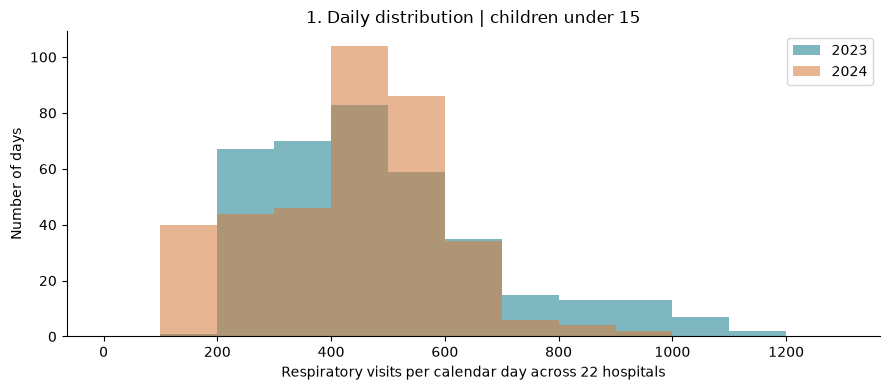

,age_group,year,respiratory,all_cause,share_pct
0,Under 1,2023,45607,103475,44.0754
1,Under 1,2024,34625,88944,38.9290
2,1–4,2023,71164,196627,36.1924
3,1–4,2024,63521,187193,33.9334
4,5–14,2023,61933,312509,19.8180
5,5–14,2024,61027,321184,19.0006


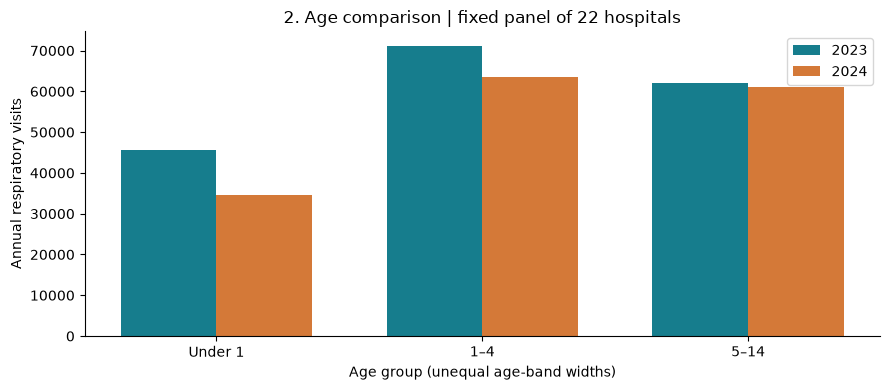

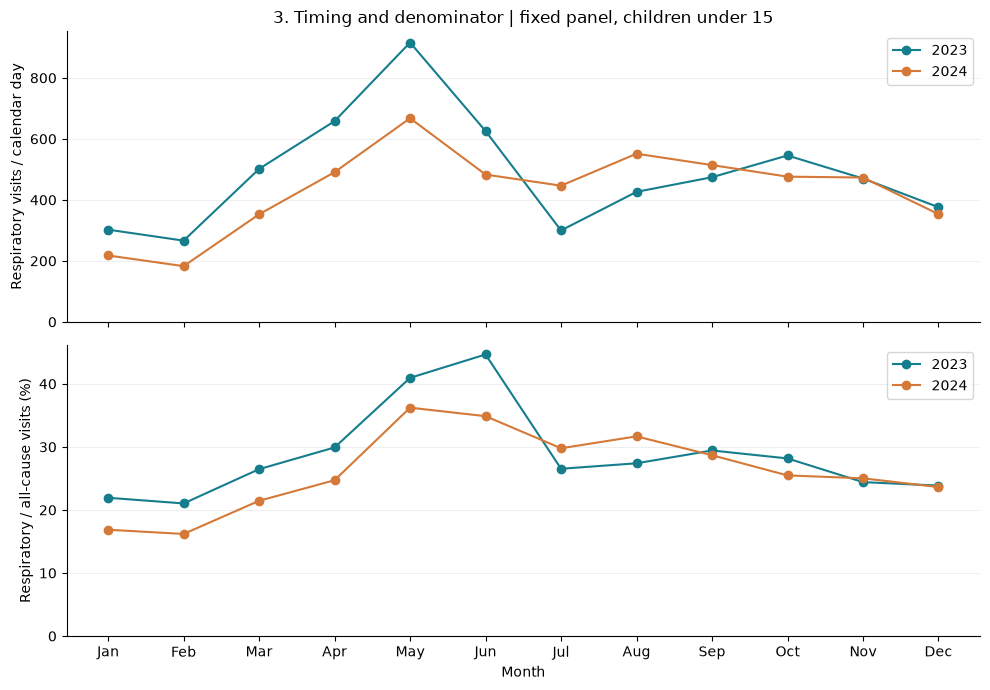

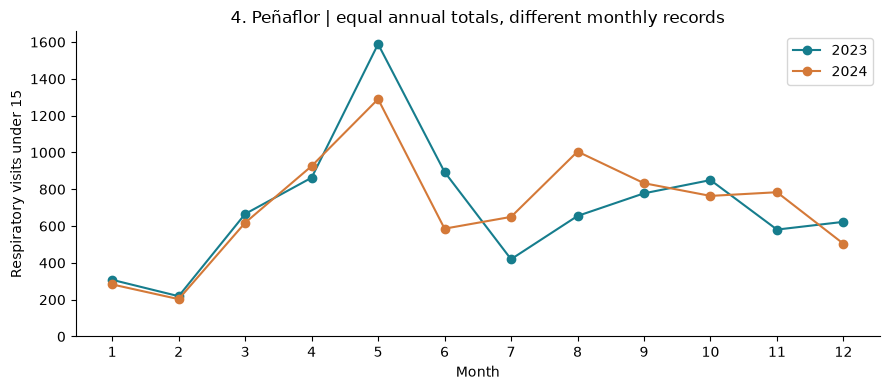

In [7]:
daily=panel_days.groupby(['year','date']).respiratory.sum().reset_index()
daily_summary=daily.groupby('year').respiratory.agg(days='size',mean='mean',median='median',std='std',minimum='min',maximum='max').reset_index()
daily_summary['q1']=daily.groupby('year').respiratory.quantile(.25).values
daily_summary['q3']=daily.groupby('year').respiratory.quantile(.75).values
daily_summary['iqr']=daily_summary.q3-daily_summary.q1
save_table(daily_summary,'daily_summary')
save_table(daily,'daily',False)
fig,ax=plt.subplots(figsize=(9,4))
bins=np.arange(0,1301,100)
for year,color in zip([2023,2024],COLORS):
    ax.hist(daily.loc[daily.year==year,'respiratory'],bins=bins,alpha=.55,label=str(year),color=color)
ax.set(xlabel='Respiratory visits per calendar day across 22 hospitals',ylabel='Number of days',title='1. Daily distribution | children under 15')
ax.legend(); show_figure(fig,'01_daily_distribution')

age_rows=[]
for age,label in zip(ages[:3],['Under 1','1–4','5–14']):
    values=panel.groupby(['year','IdCausa'])[age].sum().unstack()
    for y in [2023,2024]:
        age_rows.append({'age_group':label,'year':y,'respiratory':values.loc[y,2],'all_cause':values.loc[y,1],'share_pct':100*values.loc[y,2]/values.loc[y,1]})
age_table=pd.DataFrame(age_rows)
save_table(age_table,'age_groups')
fig,ax=plt.subplots(figsize=(9,4))
for i,(year,color) in enumerate(zip([2023,2024],COLORS)):
    g=age_table[age_table.year==year]
    ax.bar(np.arange(3)+(i-.5)*.36,g.respiratory,width=.36,color=color,label=str(year))
ax.set(xticks=range(3),xticklabels=['Under 1','1–4','5–14'],ylabel='Annual respiratory visits',xlabel='Age group (unequal age-band widths)',title='2. Age comparison | fixed panel of 22 hospitals')
ax.legend();show_figure(fig,'02_age_comparison')

monthly=aggregate(panel_days,['year','month'])
monthly['calendar_days']=pd.to_datetime(dict(year=monthly.year,month=monthly.month,day=1)).dt.days_in_month
monthly['visits_per_calendar_day']=monthly.respiratory/monthly.calendar_days
save_table(monthly,'monthly',False)
fig,axs=plt.subplots(2,1,figsize=(10,7),sharex=True)
for year,color in zip([2023,2024],COLORS):
    g=monthly[monthly.year==year]
    axs[0].plot(g.month,g.visits_per_calendar_day,'o-',color=color,label=str(year))
    axs[1].plot(g.month,g.share_pct,'o-',color=color,label=str(year))
axs[0].set(ylabel='Respiratory visits / calendar day',title='3. Timing and denominator | fixed panel, children under 15',ylim=(0,None))
axs[1].set(ylabel='Respiratory / all-cause visits (%)',xlabel='Month',xticks=range(1,13),xticklabels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'],ylim=(0,None))
for ax in axs: ax.legend();ax.grid(axis='y',alpha=.2)
show_figure(fig,'03_monthly_timing')

fig,ax=plt.subplots(figsize=(9,4))
for year,color in zip([2023,2024],COLORS):
    g=pr[pr.year==year].groupby('month').under_15.sum()
    ax.plot(g.index,g.values,'o-',color=color,label=str(year))
ax.set(xlabel='Month',ylabel='Respiratory visits under 15',title='4. Peñaflor | equal annual totals, different monthly records',xticks=range(1,13),ylim=(0,None))
ax.legend();show_figure(fig,'04_penaflor_audit')
assert monthly.groupby('year').respiratory.sum().tolist()==annual.respiratory.tolist()
assert age_table.groupby('year').respiratory.sum().tolist()==annual.respiratory.tolist()
assert daily.groupby('year').respiratory.sum().tolist()==annual.respiratory.tolist()

**Distribution:** the mean drops from 489.6 to 434.9 visits/day, but the median changes from 458 to 454. The upper distribution and maximum are lower in 2024. A uniform reduction on every day is not supported; peaks passing the validity checks remain in the analysis.

**Age comparison:** under-one visits fall by 10,982, ages 1–4 by 7,643, and ages 5–14 by 906. Under-one visits account for 56.2% of the net decline. These are service volumes from unequal-width age groups, not age-specific disease risks. Same-age respiratory shares decline in all three groups.

**Timing and denominators:** May has the highest daily respiratory volume in each year, but July, August, September and November 2024 exceed their 2023 counterparts. June 2023 has fewer respiratory visits than May but a higher respiratory share because all-cause volume also falls. Annual averages cannot justify a uniform resource reduction. Only two seasonal cycles are observed; no causal attribution or stable seasonal law is established.

## 7. Reproducible sampling demonstration
We take approximately 25% of the **18,988 paired hospital-days**, stratified by hospital and year, without replacement. Keeping the cause pair together preserves the KPI denominator; this corresponds to approximately 25% of the 37,976 cause rows. Allocation rounds each stratum to the nearest integer. Seed 42 and a fixed sort make the selection reproducible. This is a sample of available records, not a sample of children.

Compare the respiratory-share KPI and the proportion of hospital-days in June–August (a calendar-defined winter segment), including year-specific comparisons. The full available dataset is the benchmark, not only the 22 complete hospitals. A close match in one realized sample is not evidence about unobserved visits. The sample is a **separate exercise**; it is not used to fit or tune the later validation pipeline.

In [8]:
def stratified_sample(data,seed):
    rng=np.random.default_rng(seed)
    selected=[]
    for _,g in data.sort_values(['id','date']).groupby(['id','year'],sort=True):
        n=max(1,int(round(.25*len(g))))
        selected.extend(rng.choice(g.index.to_numpy(),size=n,replace=False).tolist())
    return data.loc[selected].sort_values(['id','date']).copy()
sample=stratified_sample(paired,SEED)
sample_again=stratified_sample(paired,SEED)
assert sample.index.equals(sample_again.index)
assert not sample.duplicated(['id','date']).any()
sample.to_csv(clean/'sample_25pct_hospital_days.csv',index=False,date_format='%Y-%m-%d')
comparison=[]
for period in ['All',2023,2024]:
    full=paired if period=='All' else paired[paired.year==period]
    sub=sample if period=='All' else sample[sample.year==period]
    fk=100*full.respiratory.sum()/full.all_cause.sum()
    sk=100*sub.respiratory.sum()/sub.all_cause.sum()
    comparison.append({'period':str(period),'available_rows':len(full),'sample_rows':len(sub),'sample_fraction_pct':100*len(sub)/len(full),'full_KPI_pct':fk,'sample_KPI_pct':sk,'KPI_difference_pp':sk-fk,'full_winter_rows_pct':100*full.winter.mean(),'sample_winter_rows_pct':100*sub.winter.mean(),'winter_difference_pp':100*(sub.winter.mean()-full.winter.mean())})
sample_comparison=pd.DataFrame(comparison)
save_table(sample_comparison,'sampling_comparison')
allocation=paired.groupby(['id','year']).size().rename('available_rows').to_frame().join(sample.groupby(['id','year']).size().rename('sample_rows')).reset_index()
allocation['sampling_fraction']=allocation.sample_rows/allocation.available_rows
save_table(allocation,'sampling_allocation',False)
overall=sample_comparison.iloc[0]
display(Markdown(f'**Observed sample:** {len(sample):,} of {len(paired):,} paired rows ({overall.sample_fraction_pct:.2f}%). Its KPI differs from the available-data KPI by {overall.KPI_difference_pp:+.2f} pp; its winter proportion differs by {overall.winter_difference_pp:+.2f} pp. Differences reflect finite sampling variability and rounding of allocation; no acceptance cutoff is chosen after seeing them. Stratification preserves hospital/year presence but does not force seasonal composition or KPI equality.'))

,period,available_rows,sample_rows,sample_fraction_pct,full_KPI_pct,sample_KPI_pct,KPI_difference_pp,full_winter_rows_pct,sample_winter_rows_pct,winter_difference_pp
0,All,18988,4752,25.0263,28.1996,28.2746,0.0750,25.1580,24.7264,-0.4316
1,2023,9487,2366,24.9394,29.4711,29.6056,0.1345,25.2134,24.9366,-0.2768
2,2024,9501,2386,25.1131,26.8935,26.9042,0.0106,25.1026,24.5180,-0.5846


**Observed sample:** 4,752 of 18,988 paired rows (25.03%). Its KPI differs from the available-data KPI by +0.08 pp; its winter proportion differs by -0.43 pp. Differences reflect finite sampling variability and rounding of allocation; no acceptance cutoff is chosen after seeing them. Stratification preserves hospital/year presence but does not force seasonal composition or KPI equality.

**Sampling is not splitting:** a train/test split separates analytical roles within already observed data. It does not repair missing hospitals, care settings, nonreporting or a mismatch between provider location and patient residence. A train/test score, even if one were calculated, would not demonstrate that this source represents the target population. The single sampling exercise above also cannot establish design-based uncertainty for unobserved records or independent patient outcomes.

## 8. Leakage audit and decision-time availability
Our project remains descriptive. A future candidate decision would be a review at **00:00 each day, before that day's visits**, using only already published records, for the same known hospitals. A future weekly forecast discussed in C1 would require a separately specified horizon and publication-aware weekly aggregates. No forecast is implemented here.

Calendar information is known in advance. Same-day respiratory counts are the outcome; same-day all-cause counts contain respiratory visits, and same-day respiratory shares directly use the outcome. They cannot be prospective predictors. A seven-calendar-day lag is constructed below with exact date matching; the absence of publication timestamps means its operational availability remains **uncertain**. Original values are retained for retrospective EDA, not included as contemporaneous predictors.

The full-data EDA and the C1 panel selected on 2023–2024 completeness are already forms of historical information exposure. They cannot be erased by splitting now. We keep the new processing steps separate and treat the result as a retrospective robustness check.

## 9. Actual train, validation and test datasets
We use a **chronological split shared by all hospitals**: fit on 2023, validate on January–June 2024, test on July–December 2024. The development pool is the first 18 months; its validation portion is never used to fit preprocessing. The final six-month block is about 25% of rows, which is justified by calendar periods rather than a mandatory 80/20 ratio.

A random row split would mix past and future observations and might separate related cause records. A split by hospital alone would answer transfer to new hospitals, a different question. Repeated hospital IDs across periods are intentional for future observations at known providers; **hospital-date keys and dates must not overlap**. Individual patients cannot be deduplicated because no patient identifiers exist; patient-level generalization is not claimed.

The units are one-day outcomes, so target windows do not overlap and no multi-day outcome embargo is required. Daily temporal dependence remains and prohibits interpreting rows as independent replications. For a future seven-day target, purge overlapping target windows and establish release lags first.

In [9]:
model_data=paired[paired.id.isin(universe_2023)].sort_values(['date','id']).copy()
# Exact calendar lag, not the previous seventh observed row (which could skip missing dates).
history=model_data[['id','date','respiratory']].rename(columns={'date':'lag_source_date','respiratory':'lag7_resp'})
history['date']=history.lag_source_date+pd.Timedelta(days=7)
model_data=model_data.merge(history,on=['id','date'],how='left',validate='one_to_one')
available=model_data.lag_source_date.notna()
assert ((model_data.loc[available,'date']-model_data.loc[available,'lag_source_date']).dt.days==7).all()
model_data['day_of_week']=model_data.date.dt.dayofweek
model_data['split']=np.where(model_data.date<=TRAIN_END,'train',np.where(model_data.date<=VALIDATION_END,'validation','test'))
parts={label:model_data[model_data.split==label].copy() for label in ['train','validation','test']}
train,validation,test=[parts[label] for label in ['train','validation','test']]
model_data[model_data.split!='test'].to_csv(splits_dir/'development_train_pool.csv',index=False,date_format='%Y-%m-%d')
assert train.date.max()<validation.date.min() and validation.date.max()<test.date.min()
overlap=[]
for left,right in [('train','validation'),('train','test'),('validation','test')]:
    x,y=parts[left],parts[right]
    keys_x=set(zip(x.id,x.date));keys_y=set(zip(y.id,y.date))
    common_keys=len(keys_x&keys_y)
    common_dates=len(set(x.date)&set(y.date))
    overlap.append({'pair':left+' / '+right,'common_hospital_day_keys':common_keys,'common_dates':common_dates,'common_hospitals_expected':len(set(x.id)&set(y.id))})
    assert common_keys==common_dates==0
assert sum(len(g) for g in parts.values())==len(model_data)==len(paired)
split_summary=[]
for label,g in parts.items():
    g.to_csv(splits_dir/f'{label}.csv',index=False,date_format='%Y-%m-%d')
    split_summary.append({'split':label,'start':g.date.min().date(),'end':g.date.max().date(),'hospital_days':len(g),'equivalent_cause_rows':2*len(g),'fraction_pct':100*len(g)/len(model_data),'calendar_days':g.date.nunique(),'hospitals':g.id.nunique(),'missing_lag7':g.lag7_resp.isna().sum()})
save_table(pd.DataFrame(split_summary),'split_summary')
save_table(pd.DataFrame(overlap),'split_overlap')
save_table(model_data[['id','date','split']],'split_assignments',False)
print('Development pool:',len(train)+len(validation),'hospital-days; internal validation fraction:',round(100*len(validation)/(len(train)+len(validation)),2),'%')

Development pool: 14213 hospital-days; internal validation fraction: 33.25 %


,split,start,end,hospital_days,equivalent_cause_rows,fraction_pct,calendar_days,hospitals,missing_lag7
0,train,2023-01-01,2023-12-31,9487,18974,49.9631,365,26,184
1,validation,2024-01-01,2024-06-30,4726,9452,24.8894,182,26,5
2,test,2024-07-01,2024-12-31,4775,9550,25.1475,184,26,9


,pair,common_hospital_day_keys,common_dates,common_hospitals_expected
0,train / validation,0,0,26
1,train / test,0,0,26
2,validation / test,0,0,26


### Training-only preprocessing and permitted historical context
For `lag7_resp`, we demonstrate median imputation followed by standardization. We calculate the median, imputed mean and population standard deviation **only from 2023 training rows**. We save those values and apply them to validation and test data without recalculating them. Missing lag values are due to unavailable preceding records or the beginning of the window; the outcome counts are never imputed. A missingness indicator is retained.

Lags can cross from training into validation and from earlier dates into later test dates. This represents sequential daily retrospective evaluation: a past observation can become historical context, but no future date or current outcome enters its feature. It is **not** a six-month forecast issued once on 1 July. Real deployment still requires verified publication timing, so this pipeline is a methodological demonstration only. No holdout information chooses variables, thresholds, split dates or preprocessing parameters.

In [10]:
median=float(train.lag7_resp.median())
train_imputed=train.lag7_resp.fillna(median)
mean=float(train_imputed.mean())
std=float(train_imputed.std(ddof=0))
assert np.isfinite([median,mean,std]).all() and std>0
parameters={'fit_split':'train','fit_start':str(train.date.min().date()),'fit_end':str(train.date.max().date()),'fit_rows':len(train),'feature':'lag7_resp','median':median,'mean_after_imputation':mean,'std_after_imputation_ddof0':std}
(splits_dir/'preprocessing_parameters.json').write_text(json.dumps(parameters,indent=2),encoding='utf-8')
def transform_lag(data,parameters):
    result=data[['id','date','day_of_week']].copy()
    result['lag7_missing']=data.lag7_resp.isna().astype(int)
    result['lag7_imputed']=data.lag7_resp.fillna(parameters['median'])
    result['lag7_standardized']=(result.lag7_imputed-parameters['mean_after_imputation'])/parameters['std_after_imputation_ddof0']
    return result
transform_report=[]
for label,g in parts.items():
    x=transform_lag(g,parameters)
    assert x[['lag7_imputed','lag7_standardized']].notna().all().all()
    assert (x.loc[g.lag7_resp.isna(),'lag7_imputed']==median).all()
    x.to_csv(splits_dir/f'{label}_features.csv',index=False,date_format='%Y-%m-%d')
    transform_report.append({'split':label,'rows':len(x),'imputed_lags':int(x.lag7_missing.sum()),'median_used':median,'mean_used':mean,'std_used':std,'transformed_mean':x.lag7_standardized.mean()})
display(pd.DataFrame([parameters]))
save_table(pd.DataFrame(transform_report),'preprocessing_audit')
assert np.isclose(transform_lag(train,parameters).lag7_standardized.mean(),0)
print('Parameters fitted once on training only; validation/test transformed without refitting.')

Parameters fitted once on training only; validation/test transformed without refitting.


,fit_split,fit_start,fit_end,fit_rows,feature,median,mean_after_imputation,std_after_imputation_ddof0
0,train,2023-01-01,2023-12-31,9487,lag7_resp,11.0000,19.4204,23.9666


,split,rows,imputed_lags,median_used,mean_used,std_used,transformed_mean
0,train,9487,184,11.0000,19.4204,23.9666,0.0000
1,validation,4726,5,11.0000,19.4204,23.9666,-0.1533
2,test,4775,9,11.0000,19.4204,23.9666,-0.0234


In [11]:
leakage_audit=pd.DataFrame([
 ('Target-derived / contemporaneous features','present',f'{len(paired):,} same-day all-cause counts contain respiratory visits; share uses the outcome','Would reveal outcome information','Use only calendar and exact lag for demonstration; retain contemporaneous columns only for EDA and audit'),
 ('Future dates in constructed lag','absent',f'{int(available.sum()):,} available lag links are exactly 7 days earlier; one-to-one keys','Future information could inflate apparent performance','Exact-date merge and executable lag assertions; no backward fill'),
 ('Real-time publication availability','uncertain','Annual snapshots have event dates but no publication/revision timestamps','Even an event-time lag might not have been known at decision time','Do not deploy; obtain release history and enforce as-of joins'),
 ('Duplicated observations / split overlap','absent',f'Duplicate source keys = 0; all three split pairs have 0 common dates and hospital-day keys','Related observations could appear on both sides','Pair causes first; assign every hospital on a date to the same time block'),
 ('Repeated hospitals and unobserved patients','present','26 hospitals repeat across periods; no patient identifier exists','Random rows could overstate transfer to new hospitals or independent people','Chronological known-hospital scope; no new-hospital or patient-level claims'),
 ('Whole-dataset preprocessing','absent',f'Median {median:.4f}, mean {mean:.4f}, SD {std:.4f} fitted on {len(train):,} 2023 rows only','Validation/test distribution could influence transformations','Frozen parameters applied to later subsets; never impute outcomes'),
 ('Full-period completeness selection','present','C1 historical panel requires complete 2023 AND 2024 calendars','Future reporting could choose the training population','Use 2023-observed 26-hospital universe for validation; panel only for historical continuity'),
 ('Linked tables / unstable hospital labels','absent','No external clinical or outcome table is joined; dictionary only maps cause definitions','Future labels or many-to-many joins could leak or duplicate outcomes','Names excluded from feature set; ID/date lag merge validates one-to-one cardinality'),
 ('Prior EDA exposure','present','W1/C1 examined all of 2023 and 2024 before W2','Post-hoc conclusions may appear falsely confirmatory','Label holdout as retrospective robustness; seek a future unseen period for confirmation')
],columns=['risk','status','dataset_evidence','potential_consequence','mitigation'])
save_table(leakage_audit,'leakage_audit')

,risk,status,dataset_evidence,potential_consequence,mitigation
0,Target-derived / contemporaneous features,present,"18,988 same-day all-cause counts contain respiratory visits; share uses the outcome",Would reveal outcome information,Use only calendar and exact lag for demonstration; retain contemporaneous columns only for EDA and audit
1,Future dates in constructed lag,absent,"18,790 available lag links are exactly 7 days earlier; one-to-one keys",Future information could inflate apparent performance,Exact-date merge and executable lag assertions; no backward fill
2,Real-time publication availability,uncertain,Annual snapshots have event dates but no publication/revision timestamps,Even an event-time lag might not have been known at decision time,Do not deploy; obtain release history and enforce as-of joins
3,Duplicated observations / split overlap,absent,Duplicate source keys = 0; all three split pairs have 0 common dates and hospital-day keys,Related observations could appear on both sides,Pair causes first; assign every hospital on a date to the same time block
4,Repeated hospitals and unobserved patients,present,26 hospitals repeat across periods; no patient identifier exists,Random rows could overstate transfer to new hospitals or independent people,Chronological known-hospital scope; no new-hospital or patient-level claims
5,Whole-dataset preprocessing,absent,"Median 11.0000, mean 19.4204, SD 23.9666 fitted on 9,487 2023 rows only",Validation/test distribution could influence transformations,Frozen parameters applied to later subsets; never impute outcomes
6,Full-period completeness selection,present,C1 historical panel requires complete 2023 AND 2024 calendars,Future reporting could choose the training population,Use 2023-observed 26-hospital universe for validation; panel only for historical continuity
7,Linked tables / unstable hospital labels,absent,No external clinical or outcome table is joined; dictionary only maps cause definitions,Future labels or many-to-many joins could leak or duplicate outcomes,Names excluded from feature set; ID/date lag merge validates one-to-one cardinality
8,Prior EDA exposure,present,W1/C1 examined all of 2023 and 2024 before W2,Post-hoc conclusions may appear falsely confirmatory,Label holdout as retrospective robustness; seek a future unseen period for confirmation


## 10. Internal validation and final temporal robustness results
The rule for interpretation is fixed before computing the following comparison: compare each 2024 half with the **same months of 2023** using all available hospital-days in the 26-hospital scope. Report matched-scope KPI, counts and observed-day intensity. Jan–June is the internal validation check; July–December is the final test-period check. This helps expose temporal instability, not predictive accuracy. Neither test results nor the sampling output are fed back into fitting.

Calendar halves differ in seasonal composition, so a naive comparison of 2023 as a whole with either 2024 half would be misleading. Leap year and missing reports still affect raw counts; observed hospital-day intensity is included, without estimating visits on missing days. The complete panel is a secondary historical sensitivity, not the population used to fit transformations.

In [12]:
robustness=[]
for scope,data in [('All observed hospitals',paired),('Historical complete panel',panel_days)]:
    for label,months in [('Internal validation: Jan–Jun',range(1,7)),('Final test: Jul–Dec',range(7,13))]:
        selected=data[data.month.isin(months)]
        by_year=aggregate(selected,['year']).set_index('year')
        n=selected.groupby('year').size()
        robustness.append({'scope':scope,'comparison':label,'baseline_2023_visits':by_year.loc[2023,'respiratory'],'observed_2024_visits':by_year.loc[2024,'respiratory'],'count_change_pct':100*(by_year.loc[2024,'respiratory']/by_year.loc[2023,'respiratory']-1),'share_2023_pct':by_year.loc[2023,'share_pct'],'share_2024_pct':by_year.loc[2024,'share_pct'],'share_change_pp':by_year.loc[2024,'share_pct']-by_year.loc[2023,'share_pct'],'hospital_days_2023':n.loc[2023],'hospital_days_2024':n.loc[2024],'observed_day_intensity_change_pct':100*((by_year.loc[2024,'respiratory']/n.loc[2024])/(by_year.loc[2023,'respiratory']/n.loc[2023])-1)})
robustness=pd.DataFrame(robustness)
save_table(robustness,'temporal_robustness')
print('No model fitted; no predictive accuracy metric calculated; no parameters refitted after holdout inspection.')

No model fitted; no predictive accuracy metric calculated; no parameters refitted after holdout inspection.


,scope,comparison,baseline_2023_visits,observed_2024_visits,count_change_pct,share_2023_pct,share_2024_pct,share_change_pp,hospital_days_2023,hospital_days_2024,observed_day_intensity_change_pct
0,All observed hospitals,Internal validation: Jan–Jun,102470,75079,-26.7308,31.8941,26.1200,-5.7741,4706,4726,-27.0408
1,All observed hospitals,Final test: Jul–Dec,81944,88753,8.3093,26.9143,27.5846,0.6704,4781,4775,8.4454
2,Historical complete panel,Internal validation: Jan–Jun,99294,72903,-26.5786,31.5883,25.8490,-5.7393,3982,4004,-26.9821
3,Historical complete panel,Final test: Jul–Dec,79410,86270,8.6387,26.6233,27.3624,0.7391,4048,4048,8.6387


**The temporal check changes the interpretation.** Across all 26 observed hospitals, January–June respiratory visits fall from **102,470 to 75,079 (−26.73%)**, while July–December visits rise from **81,944 to 88,753 (+8.31%)**. The final test-period respiratory share rises from **26.91% to 27.58% (+0.67 pp)**. The annual decline remains an accurate retrospective total, but it **does not persist across both calendar halves**. The complete-panel comparison above checks whether this reversal is merely caused by the four excluded providers.

This extends C1's warning about individual monthly increases: an annual reduction is not a stable rule for later demand, and a uniform resource reduction is unsupported. The split did not manufacture a new independent replication, since both years had already been explored. More recent unseen data, release timestamps and an explicitly prospective protocol are required for genuine confirmation. No statistical significance or high predictive accuracy is claimed.

## 11. Feedback-to-action record and changed conclusions
The first three entries address the feedback we received after C1. We added three self-audit items about our group label, panel selection and interpretation of the annual decline. The evidence column points to the calculations behind each correction.

In [13]:
feedback=pd.DataFrame([
 ('C1 instructor feedback','Slide 5: 19.17% in 2023 vs report 29.17%; −2.52 pp inconsistent','Recompute 178,704 / 612,611 × 100 = 29.17%; correct current KPI to 29.17% -> 26.65%, −2.52 pp','Section 4; annual_corrected.csv','The decline survives; slide baseline was a transcription inconsistency'),
 ('C1 instructor feedback','Complete panel of 22 may select the population','Define target/observed/analytical populations; compare panel, excluded four and all 26; validation uses 2023-known universe','Sections 5, 7, 9; coverage_sensitivity.csv, sampling_comparison.csv','Annual direction robust to observed scope; representativeness not established'),
 ('C1 instructor feedback','Peñaflor 8,446 in both years requires review','Rebuild from source; inspect age/month/day changes, keys, leap day and exclusion sensitivity','Sections 2, 4, 5; penaflor_age_audit.csv, penaflor_daily_comparison.csv','Retain source totals; annual equality is not a copied daily series; reporting accuracy still uncertain'),
 ('Self-audit','W1 archive and C1 slide cover use Group 10','Use confirmed Group 09 in W2; preserve historical artifacts and explicitly record mismatch','Opening scope; legacy/README.md','Administrative label corrected without changing project history'),
 ('Self-audit','Full-period panel selection could leak future reporting into validation','Separate historical panel EDA from chronological validation on all 26 IDs observed in 2023','Sections 8–9; leakage_audit.csv, split_summary.csv','Validation concerns future dates at known hospitals, not completeness-selected providers'),
 ('Self-audit','Annual decline could be overgeneralized to later periods','Implement validation and test blocks; compare same-month 2023 baseline; fit preprocessing on 2023 only','Sections 9–10; preprocessing_audit.csv, temporal_robustness.csv','Second-half 2024 counts rise 8.31% across observed hospitals; annual decline is not temporally uniform')
],columns=['source','issue','correction','notebook_evidence','changed_conclusion'])
save_table(feedback,'feedback_to_action')

,source,issue,correction,notebook_evidence,changed_conclusion
0,C1 instructor feedback,Slide 5: 19.17% in 2023 vs report 29.17%; −2.52 pp inconsistent,"Recompute 178,704 / 612,611 × 100 = 29.17%; correct current KPI to 29.17% -> 26.65%, −2.52 pp",Section 4; annual_corrected.csv,The decline survives; slide baseline was a transcription inconsistency
1,C1 instructor feedback,Complete panel of 22 may select the population,"Define target/observed/analytical populations; compare panel, excluded four and all 26; validation uses 2023-known universe","Sections 5, 7, 9; coverage_sensitivity.csv, sampling_comparison.csv",Annual direction robust to observed scope; representativeness not established
2,C1 instructor feedback,"Peñaflor 8,446 in both years requires review","Rebuild from source; inspect age/month/day changes, keys, leap day and exclusion sensitivity","Sections 2, 4, 5; penaflor_age_audit.csv, penaflor_daily_comparison.csv",Retain source totals; annual equality is not a copied daily series; reporting accuracy still uncertain
3,Self-audit,W1 archive and C1 slide cover use Group 10,Use confirmed Group 09 in W2; preserve historical artifacts and explicitly record mismatch,Opening scope; legacy/README.md,Administrative label corrected without changing project history
4,Self-audit,Full-period panel selection could leak future reporting into validation,Separate historical panel EDA from chronological validation on all 26 IDs observed in 2023,"Sections 8–9; leakage_audit.csv, split_summary.csv","Validation concerns future dates at known hospitals, not completeness-selected providers"
5,Self-audit,Annual decline could be overgeneralized to later periods,Implement validation and test blocks; compare same-month 2023 baseline; fit preprocessing on 2023 only,"Sections 9–10; preprocessing_audit.csv, temporal_robustness.csv",Second-half 2024 counts rise 8.31% across observed hospitals; annual decline is not temporally uniform


## 12. Reproducibility, limitations and AI-use disclosure
**Observed:** source fingerprints, row counts, keys, age sums, cause pairing, saved-data equality, aggregate reconciliation, sampling reproducibility and split disjointness are checked by executable code. Numerical results come from the supplied snapshots, rebuilt in this run when the default source mode is enabled.

**Assumptions:** provider classification and recorded count definitions are used as supplied; a stable ID denotes the same provider; the hypothetical operational setting concerns future dates at known hospitals. These assumptions do not establish unchanged service organization, exhaustive reporting, or timely publication.

**Managerial recommendation:** review the timing and age composition of demand with hospital detail. Obtain current attendance, severity, capacity and waiting-time information before resource decisions. Investigate publication delays before any forecasting extension. Do not infer causality, patient risk or quality from these aggregate records.

**AI-use disclosure:** We used OpenAI Codex extensively to help develop the code, prepare figures, draft explanations in English and review the assignment requirements. The results are checked through the executable controls shown in this notebook, including source fingerprints, totals, sampling and split checks. We are responsible for verifying the results and explaining our methodological choices. The source files and earlier submissions are retained for review.

We keep W1/C1 in `legacy/`. The README explains the data sources and how to run the notebook. Our submission must include the project repository link and the W2 tag or commit.

In [14]:
required_tables=['annual_corrected','quality_checks','row_counts','sampling_comparison','leakage_audit','split_summary','split_overlap','preprocessing_audit','temporal_robustness','feedback_to_action']
assert all((tables/(name+'.csv')).exists() for name in required_tables)
assert len(feedback)>=3 and len(leakage_audit)>=4
assert len(list(figures.glob('*.png')))>=3
assert len(model_data)==len(paired) and len(sample)==len(sample_again)
assert not (pd.DataFrame(checks).status=='FAIL').any()
run_record={'group':'09','seed':SEED,'mode':'full-source' if REBUILD_FROM_SOURCE else 'verified-extract','source_rows_scanned':sum(x['source_rows_scanned_this_run'] or 0 for x in scan_log),'selected_cause_rows':len(df),'paired_hospital_days':len(paired),'panel_hospitals':len(panel_ids),'observed_hospitals':paired.id.nunique(),'sample_rows':len(sample),'train_rows':len(train),'validation_rows':len(validation),'test_rows':len(test),'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'all_blocking_checks_passed':True,'predictive_model_fitted':False}
(tables/'execution_record.json').write_text(json.dumps(run_record,indent=2),encoding='utf-8')
display(pd.DataFrame([run_record]))
print('Notebook completed: all blocking checks passed. REVIEW flags document limitations, not silently removed observations.')

Notebook completed: all blocking checks passed. REVIEW flags document limitations, not silently removed observations.


,group,seed,mode,source_rows_scanned,selected_cause_rows,paired_hospital_days,panel_hospitals,observed_hospitals,sample_rows,train_rows,validation_rows,test_rows,python,pandas,numpy,all_blocking_checks_passed,predictive_model_fitted
0,09,42,full-source,17872309,37976,18988,22,26,4752,9487,4726,4775,3.12.14,3.0.1,2.5.4,True,False


## 13. Management summary

C1's 2023 respiratory share is corrected to 29.17%, consistent with the report and a decline to 26.65% in 2024. The 22-hospital panel records 10.93% fewer respiratory visits; the broader 26-hospital dataset records 11.16% fewer. These comparisons support an annual decline within observed records, not regional representativeness. Peñaflor's equal annual totals are reproduced from the source files, but its daily, monthly and age patterns differ, so the counts are retained with reporting uncertainty acknowledged.

The temporal robustness check materially qualifies the annual finding: across all observed hospitals, January–June visits fall 26.73%, while July–December visits rise 8.31%. Managers should therefore review timing, age composition and local demand rather than apply a uniform reduction. Chronological subsets and training-only preprocessing demonstrate separation of analytical roles, but prior exploration prevents claiming an untouched test. The next step is to obtain current data, verify publication delays and examine capacity and severity before operational changes. Causal explanations remain untested.